# Variational Autoencoders on CelebA Images

## Imports & Hyperparameters

In [1]:
import os
import zipfile
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms, utils

# --- Hyperparameters ---
IMAGE_SIZE    = 32
CHANNELS      = 3
BATCH_SIZE    = 32       # adapté pour 300 images
NUM_FEATURES  = 128
Z_DIM         = 200
LEARNING_RATE = 0.0005
EPOCHS        = 30
BETA          = 2000     # poids sur la reconstruction loss
LOAD_MODEL    = False

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {DEVICE}")

Using device: cpu


## 1 : Dataset Preparation and Exploration

On extrait **300 images** directement depuis le ZIP sans tout décompresser, ainsi que le CSV des attributs.

**Pourquoi [0,1] et pas [-1,1] ?** On utilise Sigmoid en sortie → valeurs déjà dans [0,1].  
**Pourquoi `drop_last=True` ?** Évite les petits batches qui cassent le BatchNorm.

In [2]:
# ============================================================
# MODIFIE CE CHEMIN selon l'emplacement de ton zip
ZIP_PATH   = r"H:\Downloads\archive.zip"
SUBSET_DIR = "./celeba_subset"    # dossier de destination
N_IMAGES   = 300                  # nombre d'images à extraire
# ============================================================

img_out_dir = os.path.join(SUBSET_DIR, "img_align_celeba")
os.makedirs(img_out_dir, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    all_files = zf.namelist()

    # Extraire les N premiers .jpg
    jpg_files = sorted([f for f in all_files if f.lower().endswith(".jpg")])[:N_IMAGES]
    print(f"Extraction de {len(jpg_files)} images...")
    for jpg_path in jpg_files:
        dest = os.path.join(img_out_dir, os.path.basename(jpg_path))
        if not os.path.exists(dest):
            with zf.open(jpg_path) as src, open(dest, "wb") as dst:
                dst.write(src.read())

    # Extraire le CSV d'attributs
    csv_files = [f for f in all_files if f.endswith("list_attr_celeba.csv")]
    if csv_files:
        csv_dest = os.path.join(SUBSET_DIR, "list_attr_celeba.csv")
        if not os.path.exists(csv_dest):
            with zf.open(csv_files[0]) as src, open(csv_dest, "wb") as dst:
                dst.write(src.read())
        print(f"CSV extrait : {csv_dest}")
    else:
        print("CSV non trouvé dans le zip.")

print(f"Images extraites : {len(os.listdir(img_out_dir))}")

Extraction de 300 images...
CSV extrait : ./celeba_subset\list_attr_celeba.csv
Images extraites : 300


In [3]:
DATA_PATH     = img_out_dir
attr_csv_path = os.path.join(SUBSET_DIR, "list_attr_celeba.csv")

transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor()   # valeurs dans [0, 1]
])

class FlatImageFolder(Dataset):
    """Dataset pour un dossier plat de .jpg (sans sous-dossiers de classes)."""
    def __init__(self, folder, transform=None):
        self.paths = sorted([
            os.path.join(folder, f) for f in os.listdir(folder)
            if f.lower().endswith(".jpg")
        ])
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, 0   # label fictif

train_dataset = FlatImageFolder(DATA_PATH, transform=transform)
train_loader  = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)

print(f"Dataset size: {len(train_dataset)} images")
print(f"Number of batches: {len(train_loader)}")

Dataset size: 300 images
Number of batches: 9


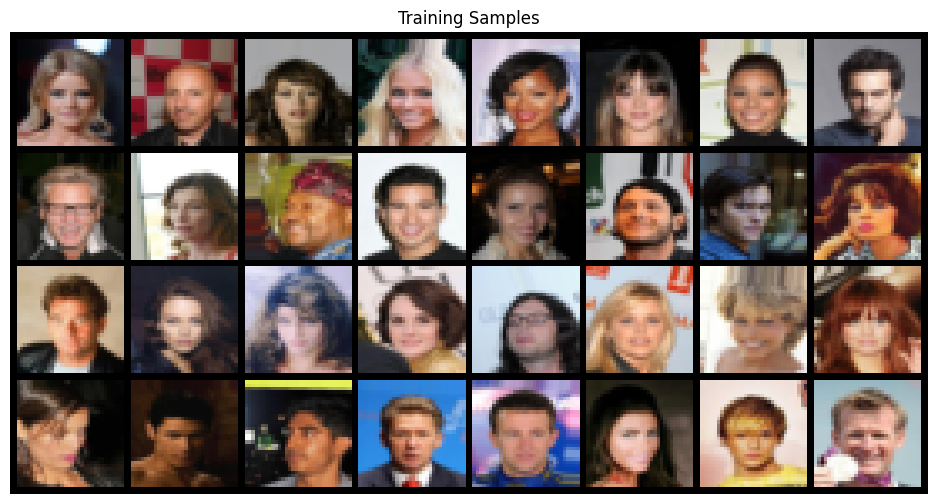

In [4]:
def show_batch(images, title=""):
    grid_img = utils.make_grid(images, nrow=8)
    plt.figure(figsize=(12, 6))
    plt.imshow(grid_img.permute(1, 2, 0).cpu().numpy())
    plt.title(title)
    plt.axis("off")
    plt.show()

data_iter = iter(train_loader)
images, _ = next(data_iter)
show_batch(images, title="Training Samples")

## 2 : Model Architecture

### 2.1 Encoder
- 4 × Conv2d stride=2 : 32×32 → 16 → 8 → 4 → **2×2**
- BatchNorm + LeakyReLU(0.2) après chaque conv
- Flatten → deux têtes FC : **μ** et **log(σ²)**

`fc_in = 128 × 2 × 2 = 512`

In [5]:
class Encoder(nn.Module):
    def __init__(self, z_dim=Z_DIM):
        super().__init__()
        self.z_dim = z_dim
        self.net = nn.Sequential(
            nn.Conv2d(CHANNELS, NUM_FEATURES, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(NUM_FEATURES),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(NUM_FEATURES, NUM_FEATURES, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(NUM_FEATURES),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(NUM_FEATURES, NUM_FEATURES, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(NUM_FEATURES),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(NUM_FEATURES, NUM_FEATURES, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(NUM_FEATURES),
            nn.LeakyReLU(0.2, inplace=True)
        )
        self.flatten = nn.Flatten()
        fc_in_features = NUM_FEATURES * (IMAGE_SIZE // 2**4) ** 2  # 128*2*2 = 512
        self.mu     = nn.Linear(fc_in_features, z_dim)
        self.logvar = nn.Linear(fc_in_features, z_dim)

    def forward(self, x):
        x      = self.net(x)
        x      = self.flatten(x)
        mu     = self.mu(x)
        logvar = self.logvar(x)
        return mu, logvar

### 2.2 Sampling — Reparameterization Trick

> z = μ + σ × ε,  ε ~ N(0, I)

Déplacer le bruit ε hors du graphe de calcul permet à la backprop de traverser μ et σ.

In [6]:
class Sampling(nn.Module):
    def forward(self, mu, logvar):
        std = torch.exp(0.5 * logvar)   # σ
        eps = torch.randn_like(std)     # ε ~ N(0,I)
        return mu + std * eps

### 2.3 Decoder

1. Linear : Z_DIM → 512
2. Reshape → (NUM_FEATURES, 2, 2)
3. 4 × ConvTranspose2d stride=2 : 2 → 4 → 8 → 16 → **32×32**
4. Sigmoid → valeurs dans [0,1]

**Pourquoi BatchNorm + LeakyReLU dans le décodeur ?**  
BatchNorm stabilise l'upsampling ; LeakyReLU évite les neurones morts dans les premières couches.

**Comment le dernier ConvTranspose2d atteint 32×32 ?**  
4 convolutions transposées stride=2, output_padding=1 : 2→4→8→16→32.

In [7]:
class Decoder(nn.Module):
    def __init__(self, z_dim=Z_DIM):
        super().__init__()
        self.z_dim = z_dim
        fc_out_features = NUM_FEATURES * (IMAGE_SIZE // 2**4) ** 2  # 512

        self.fc = nn.Sequential(
            nn.Linear(z_dim, fc_out_features),
            nn.BatchNorm1d(fc_out_features),
            nn.LeakyReLU(0.2, inplace=True)
        )
        self.deconv = nn.Sequential(
            nn.ConvTranspose2d(NUM_FEATURES, NUM_FEATURES, 3, stride=2, padding=1, output_padding=1),
            nn.BatchNorm2d(NUM_FEATURES),
            nn.LeakyReLU(0.2, inplace=True),

            nn.ConvTranspose2d(NUM_FEATURES, NUM_FEATURES, 3, stride=2, padding=1, output_padding=1),
            nn.BatchNorm2d(NUM_FEATURES),
            nn.LeakyReLU(0.2, inplace=True),

            nn.ConvTranspose2d(NUM_FEATURES, NUM_FEATURES, 3, stride=2, padding=1, output_padding=1),
            nn.BatchNorm2d(NUM_FEATURES),
            nn.LeakyReLU(0.2, inplace=True),

            nn.ConvTranspose2d(NUM_FEATURES, CHANNELS, 3, stride=2, padding=1, output_padding=1),
            nn.Sigmoid()   # valeurs dans [0,1]
        )

    def forward(self, z):
        x = self.fc(z)
        x = x.view(-1, NUM_FEATURES, IMAGE_SIZE // 2**4, IMAGE_SIZE // 2**4)  # (N,128,2,2)
        x = self.deconv(x)
        return x

### 2.4 All Together — VAE

In [8]:
class VAE(nn.Module):
    def __init__(self, z_dim=Z_DIM):
        super().__init__()
        self.encoder  = Encoder(z_dim)
        self.decoder  = Decoder(z_dim)
        self.sampling = Sampling()

    def forward(self, x):
        mu, logvar = self.encoder(x)
        z          = self.sampling(mu, logvar)
        recon      = self.decoder(z)
        return mu, logvar, recon, z

# Test de cohérence des dimensions
x_test = torch.randn(4, CHANNELS, IMAGE_SIZE, IMAGE_SIZE)
vae_test = VAE()
mu_t, logvar_t, recon_t, z_t = vae_test(x_test)
assert recon_t.shape == x_test.shape, "Output shape mismatch!"
print(f"Input:  {x_test.shape}  →  Recon: {recon_t.shape}")
print(f"mu: {mu_t.shape}  |  logvar: {logvar_t.shape}  |  z: {z_t.shape}")
print("Dimension test passed!")

Input:  torch.Size([4, 3, 32, 32])  →  Recon: torch.Size([4, 3, 32, 32])
mu: torch.Size([4, 200])  |  logvar: torch.Size([4, 200])  |  z: torch.Size([4, 200])
Dimension test passed!


## 3 : VAE Loss Function

### 3.1 Reconstruction Loss
MSE (`reduction='sum'`) — mieux adapté aux intensités continues des visages.

### 3.2 KL Divergence
> KL = −½ Σ (1 + log σ² − μ² − σ²)

Pondéré par **β/N** pour contrôler le compromis reconstruction ↔ régularisation.

In [9]:
def vae_loss_fn(x, recon, mu, logvar, beta=BETA):
    """
    x, recon  : (N, CHANNELS, IMAGE_SIZE, IMAGE_SIZE)
    mu, logvar: (N, Z_DIM)
    Retourne  : total_loss, recon_loss, kl_loss
    """
    recon_loss = F.mse_loss(recon, x, reduction="sum")
    kl         = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    kl_loss    = kl / x.size(0)
    total_loss = recon_loss + kl_loss * (beta / x.size(0))
    return total_loss, recon_loss, kl_loss

## 4 : Training Loop

In [10]:
model     = VAE(Z_DIM).to(DEVICE)
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

if LOAD_MODEL and os.path.exists("./models/vae_face.pt"):
    print("Loading existing model...")
    model.load_state_dict(torch.load("./models/vae_face.pt", map_location=DEVICE))

for epoch in range(EPOCHS):
    model.train()
    total_loss_val, total_rec_val, total_kl_val = 0.0, 0.0, 0.0

    for batch_idx, (x, _) in enumerate(train_loader):
        x = x.to(DEVICE)
        optimizer.zero_grad()

        mu, logvar, recon, _ = model(x)
        loss, rec_loss, kl_loss = vae_loss_fn(x, recon, mu, logvar, BETA)

        loss.backward()
        optimizer.step()

        total_loss_val += loss.item()
        total_rec_val  += rec_loss.item()
        total_kl_val   += kl_loss.item()

    n = len(train_loader)
    print(f"Epoch [{epoch+1}/{EPOCHS}] | Loss: {total_loss_val/n:.4f} | "
          f"Recon: {total_rec_val/n:.4f} | KL: {total_kl_val/n:.4f}")

Epoch [1/30] | Loss: 11661.1965 | Recon: 10849.4092 | KL: 12.9886
Epoch [2/30] | Loss: 7431.0686 | Recon: 6909.3716 | KL: 8.3472
Epoch [3/30] | Loss: 6175.9910 | Recon: 5748.8259 | KL: 6.8346
Epoch [4/30] | Loss: 5520.3693 | Recon: 4989.6772 | KL: 8.4911
Epoch [5/30] | Loss: 5100.1784 | Recon: 4447.8988 | KL: 10.4365
Epoch [6/30] | Loss: 4892.0306 | Recon: 4238.4721 | KL: 10.4569
Epoch [7/30] | Loss: 4800.7575 | Recon: 4106.1934 | KL: 11.1130
Epoch [8/30] | Loss: 4641.2807 | Recon: 3934.2319 | KL: 11.3128
Epoch [9/30] | Loss: 4504.8320 | Recon: 3827.6768 | KL: 10.8345
Epoch [10/30] | Loss: 4492.7662 | Recon: 3796.2260 | KL: 11.1446
Epoch [11/30] | Loss: 4569.5110 | Recon: 3826.7947 | KL: 11.8835
Epoch [12/30] | Loss: 4468.4346 | Recon: 3694.8336 | KL: 12.3776
Epoch [13/30] | Loss: 4395.2203 | Recon: 3667.8455 | KL: 11.6380
Epoch [14/30] | Loss: 4445.8017 | Recon: 3705.8934 | KL: 11.8385
Epoch [15/30] | Loss: 4361.5259 | Recon: 3628.0479 | KL: 11.7356
Epoch [16/30] | Loss: 4289.4124 | R

In [11]:
# Chargement d'un modèle pré-entraîné (optionnel)
# path = "./models/vae_face.pt"
# model.load_state_dict(torch.load(path, map_location=DEVICE))
# model.eval()

## 5 : Generating and Saving Images

Model saved to ./models/vae_face.pt


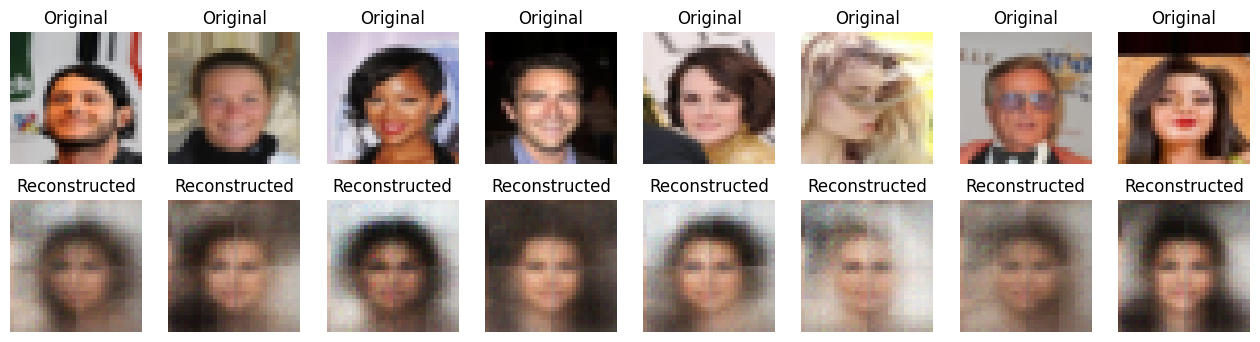

In [12]:
os.makedirs("./models", exist_ok=True)
torch.save(model.state_dict(), "./models/vae_face.pt")
print("Model saved to ./models/vae_face.pt")

model.eval()

# Reconstruction : original vs reconstruit
data_iter = iter(train_loader)
images, _ = next(data_iter)
images    = images[:8].to(DEVICE)

with torch.no_grad():
    mu, logvar, recon, _ = model(images)

def show_reconstructions(orig, recon):
    n = orig.size(0)
    plt.figure(figsize=(2*n, 4))
    for i in range(n):
        plt.subplot(2, n, i+1)
        plt.imshow(orig[i].permute(1,2,0).cpu().numpy())
        plt.title("Original")
        plt.axis("off")
    for i in range(n):
        plt.subplot(2, n, n+i+1)
        plt.imshow(recon[i].permute(1,2,0).detach().cpu().numpy())
        plt.title("Reconstructed")
        plt.axis("off")
    plt.show()

show_reconstructions(images, recon)

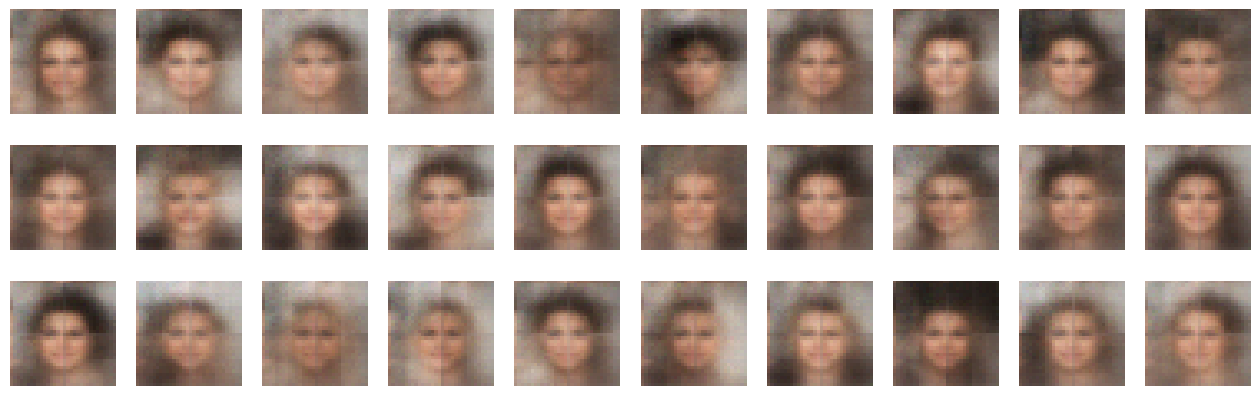

In [13]:
# Génération depuis N(0, I)
model.eval()
grid_width, grid_height = 10, 3
z_sample = torch.randn((grid_width * grid_height, Z_DIM)).to(DEVICE)

with torch.no_grad():
    recon = model.decoder(z_sample).detach()

def show_generated(recon, w=grid_width, h=grid_height):
    recon = recon.cpu()
    fig   = plt.figure(figsize=(16, 5))
    for i in range(w*h):
        ax = fig.add_subplot(h, w, i+1)
        ax.axis("off")
        ax.imshow(recon[i].permute(1,2,0).numpy())
    plt.show()

show_generated(recon)

## 6 : Next Steps and Experiments (optionnel — rien à faire, juste explorer)

1. Images en **64×64** pour plus de détail.
2. Comparer **Z_DIM=100** vs **Z_DIM=200**.
3. ReLU vs LeakyReLU.
4. Modifier **β** (500, 1000, 5000) et observer reconstruction vs structure latente.

## 7 : Building a Custom Dataset with Attributes

### 7.1 Lire le CSV (filtré sur les 300 images extraites)

In [14]:
attributes = pd.read_csv(attr_csv_path)

# Filtrer sur les images effectivement extraites
extracted_names = set(os.listdir(DATA_PATH))
attributes = attributes[attributes["image_id"].isin(extracted_names)].reset_index(drop=True)

print("Colonnes:", attributes.columns.tolist()[:10], "...")
print(f"Images avec attributs : {len(attributes)}")
print(attributes.head(3))

Colonnes: ['image_id', '5_o_Clock_Shadow', 'Arched_Eyebrows', 'Attractive', 'Bags_Under_Eyes', 'Bald', 'Bangs', 'Big_Lips', 'Big_Nose', 'Black_Hair'] ...
Images avec attributs : 300
     image_id  5_o_Clock_Shadow  Arched_Eyebrows  Attractive  Bags_Under_Eyes  \
0  000001.jpg                -1                1           1               -1   
1  000002.jpg                -1               -1          -1                1   
2  000003.jpg                -1               -1          -1               -1   

   Bald  Bangs  Big_Lips  Big_Nose  Black_Hair  ...  Sideburns  Smiling  \
0    -1     -1        -1        -1          -1  ...         -1        1   
1    -1     -1        -1         1          -1  ...         -1        1   
2    -1     -1         1        -1          -1  ...         -1       -1   

   Straight_Hair  Wavy_Hair  Wearing_Earrings  Wearing_Hat  Wearing_Lipstick  \
0              1         -1                 1           -1                 1   
1             -1         -1     

### 7.2 Custom Dataset + 7.3 DataLoader

In [15]:
LABEL = "Blond_Hair"   # exemples : "Eyeglasses", "Smiling", "Male"

class CelebADataset(Dataset):
    """
    Dataset CelebA personnalisé.
    Retourne (image_tensor, label_value) où label_value est -1 ou +1.
    """
    def __init__(self, img_folder, attr_df, label=LABEL, transform=None):
        self.img_folder = img_folder
        self.df         = attr_df
        self.label      = label
        self.transform  = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row       = self.df.iloc[idx]
        path      = os.path.join(self.img_folder, row["image_id"])
        image     = Image.open(path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        label_val = int(row[self.label])   # -1 ou +1
        return image, label_val

label_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor()
])

label_dataset = CelebADataset(DATA_PATH, attributes, label=LABEL, transform=label_transform)
label_loader  = DataLoader(label_dataset, batch_size=BATCH_SIZE, shuffle=True)

imgs, labs = next(iter(label_loader))
print(f"Images shape: {imgs.shape}  |  Labels: {labs.tolist()}")

Images shape: torch.Size([32, 3, 32, 32])  |  Labels: [-1, 1, -1, 1, -1, -1, -1, -1, -1, -1, -1, 1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, 1, -1, -1, 1, -1, -1, -1]


## 8 : Extracting an Attribute Vector in Latent Space

**Méthode :**
1. Encoder les images → collecter les **z** des positifs (attr=+1) et négatifs (attr=-1).
2. Calculer μ_pos et μ_neg.
3. **Vecteur attribut** = μ_pos − μ_neg (normalisé).

In [16]:
def get_vector_from_label(loader, vae, embedding_dim, label_name="Attribute", max_samples=10000):
    """
    Calcule le vecteur de direction de l'attribut dans l'espace latent.
    Retourne un np.array de forme (embedding_dim,).
    """
    device = next(vae.parameters()).device
    vae.eval()

    sum_POS, n_POS, mean_POS = np.zeros(embedding_dim, "float32"), 0, np.zeros(embedding_dim, "float32")
    sum_NEG, n_NEG, mean_NEG = np.zeros(embedding_dim, "float32"), 0, np.zeros(embedding_dim, "float32")
    current_vector, current_dist = np.zeros(embedding_dim, "float32"), 0.0

    print(f"label: {label_name}")
    print("n_POS | POS_move | NEG_move | distance | Δ_distance")

    for images, attr in loader:
        images = images.to(device)
        with torch.no_grad():
            mu, logvar, _, z = vae(images)

        z_np   = z.cpu().numpy()
        att_np = attr.numpy()

        z_POS = z_np[att_np ==  1]
        z_NEG = z_np[att_np == -1]

        if len(z_POS) > 0:
            sum_POS   += np.sum(z_POS, axis=0)
            old_mean   = mean_POS.copy()
            n_POS     += len(z_POS)
            mean_POS   = sum_POS / n_POS
            move_POS   = np.linalg.norm(mean_POS - old_mean)
        else:
            move_POS = 0.0

        if len(z_NEG) > 0:
            sum_NEG   += np.sum(z_NEG, axis=0)
            old_mean   = mean_NEG.copy()
            n_NEG     += len(z_NEG)
            mean_NEG   = sum_NEG / n_NEG
            move_NEG   = np.linalg.norm(mean_NEG - old_mean)
        else:
            move_NEG = 0.0

        current_vector = mean_POS - mean_NEG
        new_dist       = np.linalg.norm(current_vector)
        print(f"{n_POS:5d} | {move_POS:.3f} | {move_NEG:.3f} | {new_dist:.3f} | {new_dist-current_dist:.3f}")
        current_dist   = new_dist

        if n_POS >= max_samples and n_NEG >= max_samples:
            break
        if (move_POS + move_NEG) < 0.08 and new_dist > 1e-8:
            current_vector /= new_dist
            print(f"Found the {label_name} vector")
            break

    return current_vector


feature_vec = get_vector_from_label(label_loader, model, embedding_dim=Z_DIM, label_name=LABEL)
print(f"Feature vector shape: {feature_vec.shape}")

label: Blond_Hair
n_POS | POS_move | NEG_move | distance | Δ_distance
    2 | 9.150 | 2.981 | 9.657 | 9.657
    8 | 8.325 | 1.899 | 5.553 | -4.104
   11 | 2.378 | 1.199 | 4.699 | -0.854
   16 | 2.390 | 0.790 | 3.963 | -0.737
   22 | 1.747 | 0.567 | 3.681 | -0.282
   26 | 1.206 | 0.455 | 3.626 | -0.054
   29 | 0.985 | 0.407 | 3.476 | -0.150
   33 | 0.904 | 0.367 | 3.404 | -0.072
   36 | 0.643 | 0.357 | 3.278 | -0.126
   37 | 0.338 | 0.217 | 3.238 | -0.040
Feature vector shape: (200,)


## 9 : Using the Attribute Vector

### 9.1 Ajouter le vecteur aux images

> z' = z + α × V_attr,  α ∈ {-4, ..., +4}

On décode chaque z' pour voir l'attribut apparaître/disparaître progressivement.

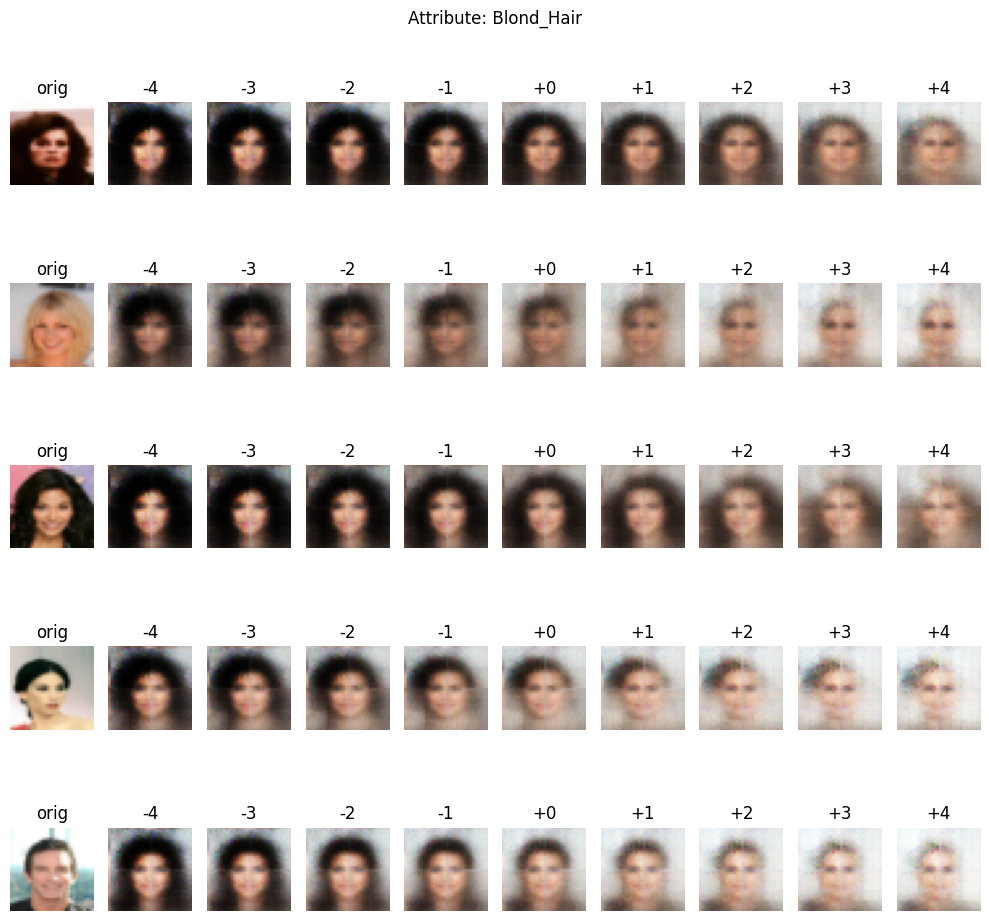

In [17]:
def add_vector_to_images(loader, vae, feature_vec, factors=None):
    if factors is None:
        factors = [-4, -3, -2, -1, 0, 1, 2, 3, 4]

    device = next(vae.parameters()).device
    vae.eval()

    images, _ = next(iter(loader))
    images    = images.to(device)

    with torch.no_grad():
        mu, logvar, _, z = vae(images)

    n_show  = min(5, images.size(0))
    fig     = plt.figure(figsize=(len(factors)+1, n_show*2))
    counter = 1

    for i in range(n_show):
        ax = fig.add_subplot(n_show, len(factors)+1, counter); counter += 1
        ax.axis("off")
        ax.imshow(images[i].cpu().permute(1,2,0).numpy())
        ax.set_title("orig")

        base_z = z[i].cpu().numpy()
        for f in factors:
            new_z = torch.from_numpy(base_z + feature_vec * f).unsqueeze(0).float().to(device)
            with torch.no_grad():
                img_f = vae.decoder(new_z)[0].cpu().permute(1,2,0).numpy()
            ax = fig.add_subplot(n_show, len(factors)+1, counter); counter += 1
            ax.axis("off")
            ax.imshow(img_f)
            ax.set_title(f"{f:+d}")

    plt.suptitle(f"Attribute: {LABEL}", fontsize=12)
    plt.tight_layout()
    plt.show()


add_vector_to_images(label_loader, model, feature_vec)

### 9.2 Morphing entre deux visages

> z(α) = (1−α) · z_A + α · z_B,  α ∈ [0,1]

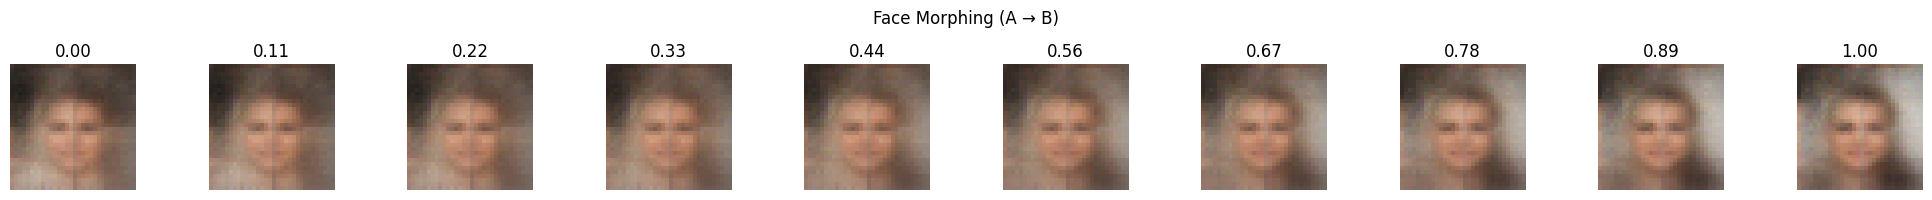

In [18]:
def morph_faces(loader, vae, steps=10):
    device = next(vae.parameters()).device
    vae.eval()

    images, _ = next(iter(loader))
    images    = images[:2].to(device)
    if images.size(0) < 2:
        print("Pas assez d'images dans le batch.")
        return

    with torch.no_grad():
        mu, logvar, _, z = vae(images)

    zA = z[0].cpu().numpy()
    zB = z[1].cpu().numpy()

    plt.figure(figsize=(2*steps, 2))
    for idx, alpha in enumerate(np.linspace(0, 1, steps), 1):
        inter_z = zA*(1-alpha) + zB*alpha
        inter_t = torch.from_numpy(inter_z).unsqueeze(0).float().to(device)
        with torch.no_grad():
            img = vae.decoder(inter_t)[0].cpu().permute(1,2,0).numpy()
        ax = plt.subplot(1, steps, idx)
        ax.imshow(img)
        ax.set_title(f"{alpha:.2f}")
        ax.axis("off")

    plt.suptitle("Face Morphing (A → B)", fontsize=12)
    plt.tight_layout()
    plt.show()


morph_faces(label_loader, model, steps=10)